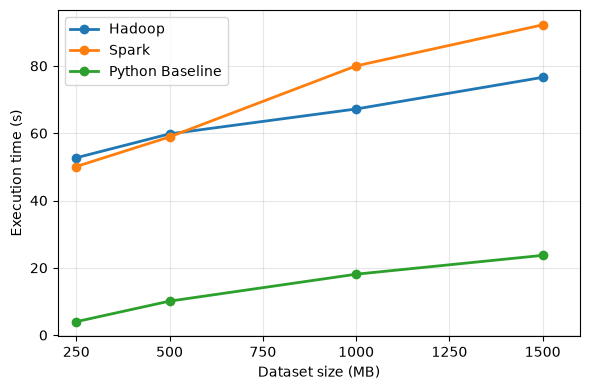

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# Load results
df = pd.read_csv("../results/benchmark.csv")

# Keep only scaling experiment
df = df[df["experiment"] == "scaling"]

# Remove invalid benchmark if necessary
df = df[~((df["engine"] == "hadoop") & (df["size_mb"] == 250) & (df["exit"] != 0))]

plt.figure(figsize=(6,4))

for engine, label in [
    ("hadoop", "Hadoop"),
    ("spark", "Spark"),
    ("baseline", "Python Baseline")
]:
    tmp = df[df.engine == engine].sort_values("size_mb")
    plt.plot(
        tmp["size_mb"],
        tmp["wall_s"],
        marker="o",
        linewidth=2,
        label=label
    )

plt.xlabel("Dataset size (MB)")
plt.ylabel("Execution time (s)")
plt.xticks(range(250, 1751, 250))
plt.xlim(200, 1600)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("scaling.pdf")
plt.show()

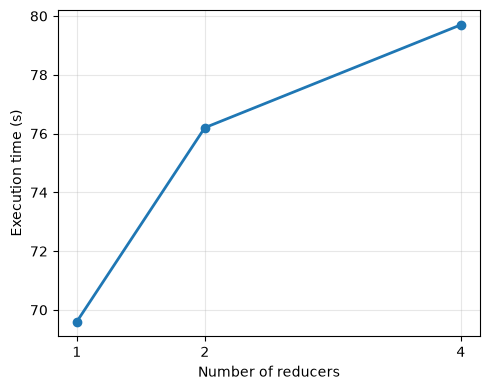

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load results
df = pd.read_csv("../results/benchmark.csv")
df = df[df["experiment"] == "reducers"]

df["reducers"] = df["param"].str.extract(r'(\d+)').astype(int)

df = df.sort_values("reducers")

plt.figure(figsize=(5,4))

plt.plot(
    df["reducers"],
    df["wall_s"],
    marker="o",
    linewidth=2
)

plt.xticks([1,2,4])
plt.xlabel("Number of reducers")
plt.ylabel("Execution time (s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("reducers.pdf")
plt.show()

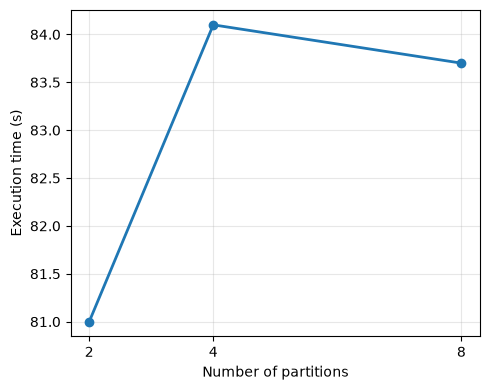

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load results
df = pd.read_csv("../results/benchmark.csv")
df = df[df["experiment"] == "partitions"]

df["partitions"] = df["param"].str.extract(r'(\d+)').astype(int)

df = df.sort_values("partitions")

plt.figure(figsize=(5,4))

plt.plot(
    df["partitions"],
    df["wall_s"],
    marker="o",
    linewidth=2
)

plt.xticks([2,4,8])
plt.xlabel("Number of partitions")
plt.ylabel("Execution time (s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("partitions.pdf")
plt.show()